In [1]:
import os
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
import torch
import pyarrow
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter

# used by the validity and stability sections at the end of the notebook
import sys, time, random, platform, pickle
from pathlib import Path
import scipy, sklearn, transformers, sentence_transformers, matplotlib
from scipy import sparse
from scipy.optimize import linear_sum_assignment
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jameswrightson/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Intro

In this notebook, I use a sentence transformer, PCA and K-means clustering to turn the free text chief complaint into ca category varibale that can be used for analysis 

# Data

Data comes from the first [notebook](/1_mimic_data.ipynb) in this repo, which must be run first 

The clustering cells below produce `chiefcomp_clustered.parquet` (the labels used in the paper) and `chiefcomp_data.pkl` (the same data with the sentence embeddings). When both files exist, the next cell loads them and the cleaning, embedding and k = 12 fit are skipped, so the paper's labels are never overwritten and the validity and stability sections at the end of the notebook run on exactly the embeddings that produced them. The PCA variance plot and the elbow plot are always drawn: they read the stored embeddings, and reuse the cached PCA matrix (`chiefcomp_pca80.npy`), variance ratios (`chiefcomp_pca_variance.npy`) and inertias (`chiefcomp_validity_k.csv`) when those exist. Delete `chiefcomp_clustered.parquet` and `chiefcomp_data.pkl` to recluster from scratch.

In [2]:
file_path = 'ed_join_cc.parquet'
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found: {file_path}. Have you run the previous notebook?")
else:
    print(f"File found: {file_path}")

File found: ed_join_cc.parquet


In [3]:
data = pd.read_parquet('ed_join_cc.parquet')
data = data[['stay_id', 'chiefcomplaint']]

In [4]:
CACHED = os.path.exists('chiefcomp_clustered.parquet') and os.path.exists('chiefcomp_data.pkl')
if CACHED:
    with open('chiefcomp_data.pkl', 'rb') as f:
        _saved = pickle.load(f)
    data, embeddings = _saved['data'], np.asarray(_saved['embeddings'], dtype=np.float32)
    _stored = pd.read_parquet('chiefcomp_clustered.parquet', columns=['stay_id', 'cluster'])
    assert (data['stay_id'].to_numpy() == _stored['stay_id'].to_numpy()).all()
    assert (data['cluster'].to_numpy() == _stored['cluster'].to_numpy()).all()
    print(f"Stored clustering loaded: {len(data):,} complaints, {data['cluster'].nunique()} clusters, embeddings {embeddings.shape}")
else:
    print('No stored clustering found: the cells below clean, embed and cluster from scratch')

Stored clustering loaded: 424,707 complaints, 12 clusters, embeddings (424707, 768)


# Create Category

Clean the text

In [5]:
if not CACHED:
    # Common abbreviations from MIMIC
    abbreviation_dict = {
        "r/o": "rule out",
        "l": "left",
        "L": "left",
        "r": "right",
        "R": "right",
        "rt.": "right",
        "s/p": "status post",
        "mvc": "motor vehicle collision",
        "ha": "headache",
        "h/a": "headache",
        "n/v": "nausea and vomiting",
        "nv": "nausea and vomiting",
        "abd": "abdomen",
        "etoh": "alcohol intoxication",
        "lbp": "lower back pain",
        "ili": "influenza-like illness",
        "post op": "post operative",
        "rle": "right lower extremity",
        "lle": "left lower extremity",
        "eval": "evaluation",
        "ped": "pedestrian",
        "b": "bilateral",
        "dvt": "deep vein thrombosis",
        "rx": "prescription",
        "rue": "right upper extremity",
        "lue": "left upper extremity",
        "ruq": "right upper quadrant",
        "rlq": "right lower quadrant",
        "luq": "left upper quadrant",
        "llq": "left lower quadrant",
        "fx": "fracture",
        "sz": "seizure",
        "inj": "injury",
        "sah": "subarachnoid hemorrhage",
        "si": "suicidal ideation",
        "hi": "homicidal ideation",
        "sob": "shortness of breath"
    }
    def clean_text(text):
        if not isinstance(text, str):
            return ''
        text = text.lower()
        # Replace abbreviations using word boundaries
        for abbr, full_form in abbreviation_dict.items():
            pattern = r'\b' + re.escape(abbr) + r'\b'
            text = re.sub(pattern, full_form, text)
        # Normalize spacing and remove non-alpha characters
        text = re.sub(r'[^a-z\s]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        # Remove selected terms
        text = re.sub(r'\b(left|right|status post|motor)\b', '', text)
        # Remove stopwords
        stop_words = set(stopwords.words('english'))
        tokens = [word for word in text.split() if word not in stop_words]
        return ' '.join(tokens)

    data['cc_cleaned'] = data['chiefcomplaint'].apply(clean_text)
else:
    print('Skipped: the stored clustering was loaded above')

Skipped: the stored clustering was loaded above


Create embeddings using a sentence transformer. The model is [this](https://huggingface.co/pritamdeka/BioBERT-mnli-snli-scinli-scitail-mednli-stsb) one 

In [6]:
if not CACHED:
    model_name = SentenceTransformer('pritamdeka/BioBERT-mnli-snli-scinli-scitail-mednli-stsb')
    embeddings = model_name.encode(data['cc_cleaned'].tolist(), show_progress_bar=True)
else:
    print('Skipped: the stored clustering was loaded above')

Skipped: the stored clustering was loaded above


Reduce the dimensions and cluster.

First, pick n for PCA

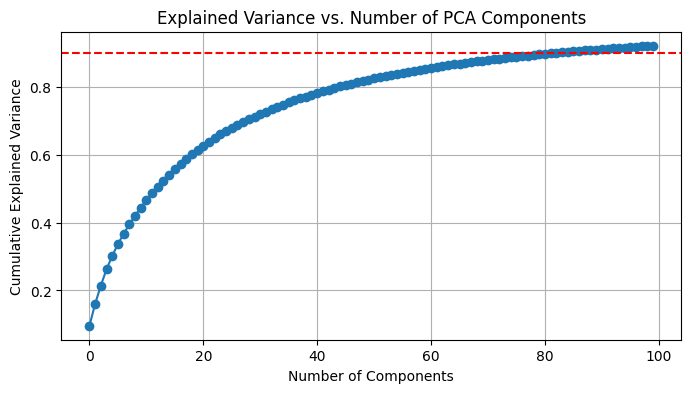

In [7]:
X = embeddings
# Explained variance of the first 100 components, cached after the first run
if os.path.exists('chiefcomp_pca_variance.npy'):
    explained = np.load('chiefcomp_pca_variance.npy')
else:
    pca_full = PCA(n_components=100, random_state=42)
    pca_full.fit(X)
    explained = pca_full.explained_variance_ratio_
    np.save('chiefcomp_pca_variance.npy', explained)

# Plot cumulative explained variance
cumulative_variance = np.cumsum(explained)

plt.figure(figsize=(8, 4))
plt.plot(cumulative_variance, marker='o')
plt.axhline(y=0.9, color='r', linestyle='--')  # commonly used threshold
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Number of PCA Components')
plt.grid(True)
plt.show()


In [8]:
# Reduce dimensions to 80 before clustering; the matrix is cached after the first run
if os.path.exists('chiefcomp_pca80.npy'):
    X_reduced = np.load('chiefcomp_pca80.npy')
else:
    pca = PCA(n_components=80, random_state=42)
    X_reduced = pca.fit_transform(X).astype(np.float32)
    np.save('chiefcomp_pca80.npy', X_reduced)


Now Get the elbow for K, with the silhouette underneath when the validity table is cached

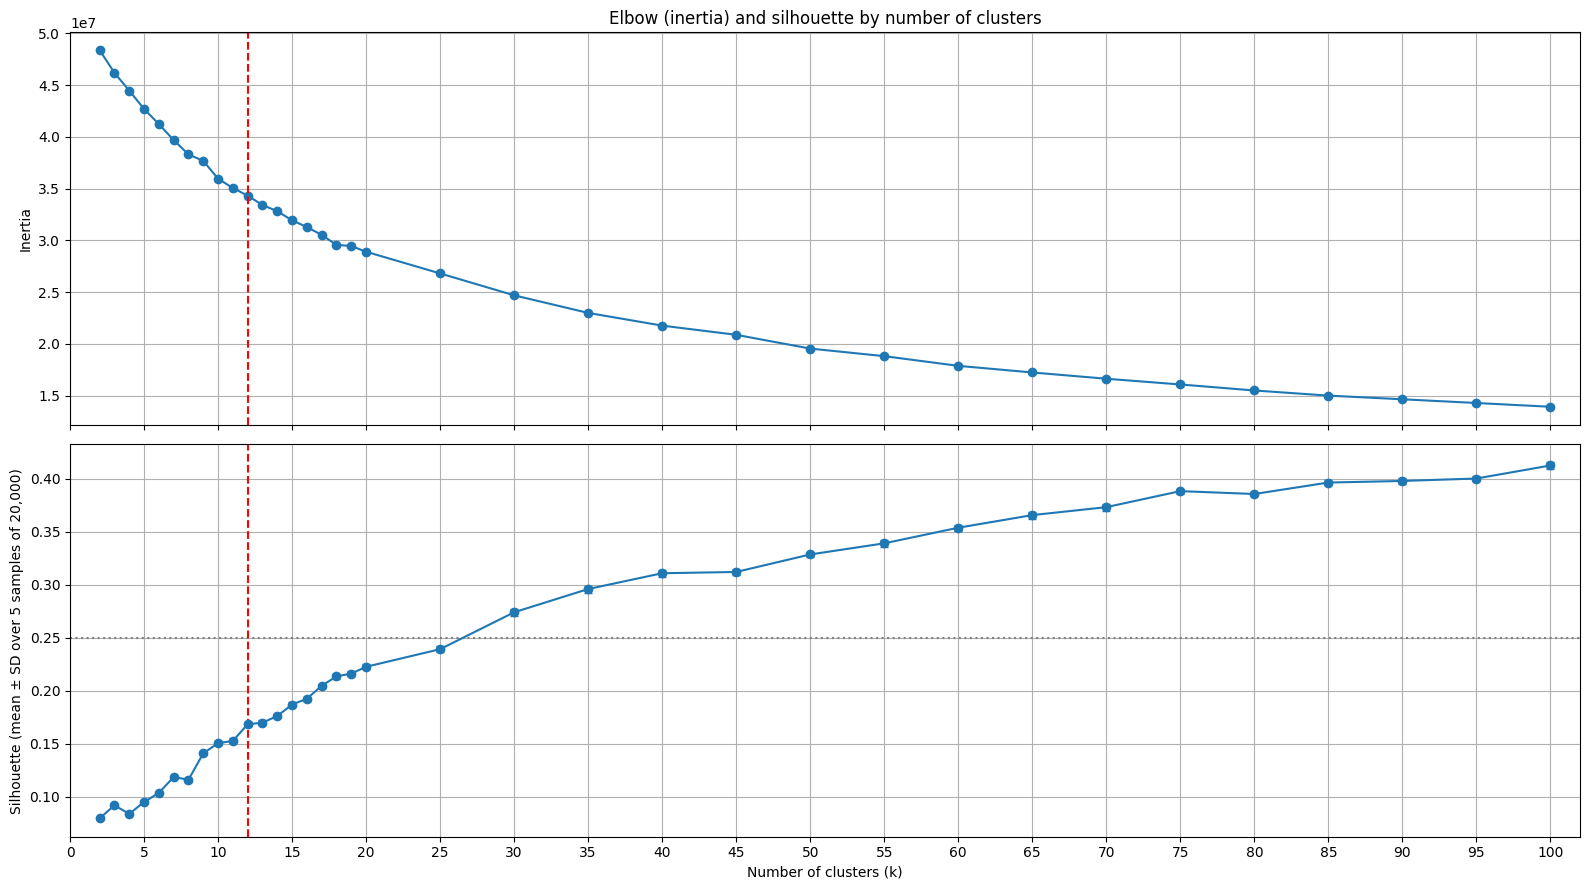

In [9]:
# Inertia and silhouette for each k; read from the validity table if it exists (same PCA matrix and seed, k = 2 to 100)
# else fit k = 2 to 19 here (inertia only; the silhouette is computed in the validity section below)
if os.path.exists('chiefcomp_validity_k.csv'):
    _val = pd.read_csv('chiefcomp_validity_k.csv')
    k_range, inertias = _val['k'].tolist(), _val['inertia'].tolist()
    sil_mean, sil_sd = _val['silhouette_mean'].tolist(), _val['silhouette_sd'].tolist()
else:
    k_range, inertias, sil_mean = list(range(2, 20)), [], None
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(X_reduced)
        inertias.append(km.inertia_)

fig, axes = plt.subplots(2 if sil_mean else 1, 1, figsize=(16, 9 if sil_mean else 5), sharex=True)
axes = np.atleast_1d(axes)
axes[0].plot(k_range, inertias, marker='o')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow (inertia) and silhouette by number of clusters')
if sil_mean:
    axes[1].errorbar(k_range, sil_mean, yerr=sil_sd, marker='o', capsize=3)
    axes[1].axhline(y=0.25, color='grey', linestyle=':')   # Kaufman & Rousseeuw: below 0.25, no substantial structure
    axes[1].set_ylabel('Silhouette (mean ± SD over 5 samples of 20,000)')
for ax in axes:
    ax.axvline(x=12, color='r', linestyle='--')
    ax.grid(True)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
axes[-1].set_xlabel('Number of clusters (k)')
plt.xlim(0, 102)
plt.tight_layout()
plt.show()


In [10]:
if not CACHED:
    # Cluster using K-means with k=12
    kmeans = KMeans(n_clusters=12, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_reduced)
    # Add back onto the original data
    data['cluster'] = cluster_labels
else:
    print('Skipped: the stored labels are kept; refitting k = 12 is done in the reproducibility section below')


Skipped: the stored labels are kept; refitting k = 12 is done in the reproducibility section below


# Analyze

How many per cluster in order

In [11]:
data['cluster'].value_counts()

cluster
7     77687
5     51399
4     48899
2     48187
0     36265
3     36012
6     30918
1     29705
9     23082
11    18052
8     12848
10    11653
Name: count, dtype: int64

In [12]:
data['cluster'].isnull().sum()

0

In [13]:
from collections import Counter

def ngram_listing(labels, title):
    """For each cluster: size, share of visits, and the 3 most common bigrams and trigrams
    with the share of the cluster's complaints that contain each one."""
    print(f'\n===== {title} =====')
    texts = data['cc_cleaned'].fillna('').astype(str).str.split()
    for c in sorted(np.unique(labels)):
        toks = texts[labels == c]; n = len(toks)
        bi, tri = Counter(), Counter()
        for t in toks:
            bi.update(set(zip(t, t[1:]))); tri.update(set(zip(t, t[1:], t[2:])))
        fmt = lambda cnt: '; '.join(f'{" ".join(g)} ({v / n * 100:.1f}%)' for g, v in cnt.most_common(3))
        print(f'\nCluster {c} (n = {n:,}, {n / len(labels) * 100:.1f}% of visits)')
        print('  bigrams:  ' + fmt(bi))
        print('  trigrams: ' + fmt(tri))

ngram_listing(data['cluster'].to_numpy(), 'k = 12, the stored labels used in the paper')



===== k = 12, the stored labels used in the paper =====



Cluster 0 (n = 36,265, 8.5% of visits)
  bigrams:  back pain (41.1%); lower back (14.4%); shoulder pain (9.3%)
  trigrams: lower back pain (14.3%); lower extremity pain (1.6%); pain arm pain (1.5%)

Cluster 1 (n = 29,705, 7.0% of visits)
  bigrams:  like illness (17.0%); influenza like (17.0%); sore throat (13.2%)
  trigrams: influenza like illness (17.0%); cough influenza like (1.7%); fever influenza like (1.7%)

Cluster 2 (n = 48,187, 11.3% of visits)
  bigrams:  vehicle collision (11.6%); mental status (9.4%); altered mental (9.2%)
  trigrams: altered mental status (9.2%); vehicle collision neck (0.9%); collision neck pain (0.8%)

Cluster 3 (n = 36,012, 8.5% of visits)
  bigrams:  chest pain (70.8%); pain dyspnea (7.2%); pain transfer (2.3%)
  trigrams: chest pain dyspnea (7.2%); pain cardiac features (2.3%); chest pain cardiac (2.3%)

Cluster 4 (n = 48,899, 11.5% of visits)
  bigrams:  shortness breath (6.3%); dyspnea exertion (2.7%); urinary retention (2.7%)
  trigrams: altered m


Cluster 5 (n = 51,399, 12.1% of visits)
  bigrams:  abdomen pain (55.9%); abdominal pain (22.5%); quadrant abdominal (12.3%)
  trigrams: quadrant abdominal pain (12.3%); lower quadrant abdominal (8.5%); upper quadrant abdominal (3.8%)

Cluster 6 (n = 30,918, 7.3% of visits)
  bigrams:  leg pain (18.0%); knee pain (16.0%); foot pain (13.1%)
  trigrams: bilateral leg swelling (1.6%); pain leg pain (1.6%); pain wound evaluation (1.6%)

Cluster 7 (n = 77,687, 18.3% of visits)
  bigrams:  wound evaluation (7.8%); abnormal labs (4.7%); vaginal bleeding (2.3%)
  trigrams: subarachnoid hemorrhage transfer (0.5%); picc line evaluation (0.4%); deep vein thrombosis (0.4%)

Cluster 8 (n = 12,848, 3.0% of visits)
  bigrams:  alcohol intoxication (87.7%); unable ambulate (12.4%); intoxication unable (11.4%)
  trigrams: alcohol intoxication unable (11.4%); intoxication unable ambulate (11.4%); pain alcohol intoxication (3.8%)

Cluster 9 (n = 23,082, 5.4% of visits)
  bigrams:  nausea vomiting (62.1%


Cluster 11 (n = 18,052, 4.3% of visits)
  bigrams:  fall transfer (8.6%); head injury (5.3%); pedestrian struck (4.8%)
  trigrams: head injury fall (3.0%); hip pain fall (2.5%); fall head injury (2.0%)


In [14]:
# The same listing for the random_state 42 reference fits at other k, from the cached labels written by the validity section
if os.path.exists('chiefcomp_ref_labels.npz'):
    _ref = np.load('chiefcomp_ref_labels.npz')
    for k in [10, 12, 13, 15, 30]:
        ngram_listing(_ref[str(k)], f'k = {k}, random_state 42 reference fit (not the stored labels)')
else:
    print('chiefcomp_ref_labels.npz not found: run the validity section first')



===== k = 10, random_state 42 reference fit (not the stored labels) =====



Cluster 0 (n = 51,986, 12.2% of visits)
  bigrams:  abdomen pain (55.3%); abdominal pain (22.6%); quadrant abdominal (12.3%)
  trigrams: quadrant abdominal pain (12.3%); lower quadrant abdominal (8.6%); upper quadrant abdominal (3.8%)

Cluster 1 (n = 62,230, 14.7% of visits)
  bigrams:  vehicle collision (8.7%); sore throat (6.4%); neck pain (6.0%)
  trigrams: influenza like illness (1.6%); pain vehicle collision (0.9%); vehicle collision neck (0.8%)

Cluster 2 (n = 32,643, 7.7% of visits)
  bigrams:  leg pain (18.4%); knee pain (15.2%); foot pain (12.4%)
  trigrams: pain leg pain (2.4%); back pain leg (2.0%); lower extremity pain (1.8%)



Cluster 3 (n = 106,377, 25.0% of visits)
  bigrams:  wound evaluation (5.9%); mental status (4.4%); altered mental (4.3%)
  trigrams: altered mental status (4.3%); influenza like illness (2.4%); subarachnoid hemorrhage transfer (0.4%)

Cluster 4 (n = 65,360, 15.4% of visits)
  bigrams:  shortness breath (4.8%); dyspnea exertion (2.1%); urinary retention (2.1%)
  trigrams: influenza like illness (1.9%); altered mental status (1.1%); cough influenza like (0.7%)

Cluster 5 (n = 42,692, 10.1% of visits)
  bigrams:  chest pain (61.8%); back pain (30.6%); lower back (10.7%)
  trigrams: lower back pain (10.7%); chest pain dyspnea (6.1%); pain cardiac features (2.0%)

Cluster 6 (n = 18,967, 4.5% of visits)
  bigrams:  fall transfer (8.2%); pain fall (6.1%); head injury (5.5%)
  trigrams: head injury fall (3.0%); hip pain fall (2.4%); back pain fall (2.3%)

Cluster 7 (n = 23,106, 5.4% of visits)
  bigrams:  nausea vomiting (62.0%); abdomen pain (29.1%); pain nausea (25.4%)
  trigrams: pain nau


Cluster 9 (n = 12,881, 3.0% of visits)
  bigrams:  alcohol intoxication (87.7%); unable ambulate (12.4%); intoxication unable (11.4%)
  trigrams: alcohol intoxication unable (11.4%); intoxication unable ambulate (11.4%); pain alcohol intoxication (3.8%)

===== k = 12, random_state 42 reference fit (not the stored labels) =====



Cluster 0 (n = 53,474, 12.6% of visits)
  bigrams:  abnormal labs (8.1%); vaginal bleeding (3.6%); urinary retention (2.9%)
  trigrams: altered mental status (1.9%); pregnant vaginal bleeding (0.6%); abnormal sodium level (0.5%)

Cluster 1 (n = 25,724, 6.1% of visits)
  bigrams:  shortness breath (9.3%); fall transfer (6.0%); head injury (3.9%)
  trigrams: head injury fall (2.2%); hip pain fall (1.7%); fall head injury (1.4%)

Cluster 2 (n = 52,195, 12.3% of visits)
  bigrams:  sore throat (7.4%); like illness (7.1%); influenza like (7.1%)
  trigrams: influenza like illness (7.1%); vehicle collision neck (0.8%); collision neck pain (0.8%)

Cluster 3 (n = 50,815, 12.0% of visits)
  bigrams:  abdomen pain (56.3%); abdominal pain (22.6%); quadrant abdominal (12.3%)
  trigrams: quadrant abdominal pain (12.3%); lower quadrant abdominal (8.5%); upper quadrant abdominal (3.9%)

Cluster 4 (n = 8,472, 2.0% of visits)
  bigrams:  suicidal ideation (94.1%); depression suicidal (8.7%); homicidal 


Cluster 6 (n = 77,597, 18.3% of visits)
  bigrams:  wound evaluation (7.8%); vehicle collision (5.7%); mental status (5.5%)
  trigrams: altered mental status (5.3%); subarachnoid hemorrhage transfer (0.5%); mental status transfer (0.5%)

Cluster 7 (n = 22,206, 5.2% of visits)
  bigrams:  arm pain (13.9%); shoulder pain (13.7%); finger laceration (6.4%)
  trigrams: pain arm pain (2.0%); chest pain arm (1.8%); pain shoulder pain (1.7%)

Cluster 8 (n = 49,139, 11.6% of visits)
  bigrams:  chest pain (52.2%); pain dyspnea (5.7%); dyspnea exertion (3.4%)
  trigrams: chest pain dyspnea (5.5%); influenza like illness (2.4%); pain cardiac features (1.7%)

Cluster 9 (n = 18,213, 4.3% of visits)
  bigrams:  back pain (84.5%); lower back (30.8%); pain leg (3.7%)
  trigrams: lower back pain (30.7%); back pain leg (3.6%); lower extremity pain (3.1%)

Cluster 10 (n = 30,928, 7.3% of visits)
  bigrams:  leg pain (17.2%); knee pain (16.0%); foot pain (13.0%)
  trigrams: pain wound evaluation (1.6%); 

... (5 outputs left out)


Cluster 12 (n = 19,586, 4.6% of visits)
  bigrams:  wound evaluation (33.6%); finger laceration (7.3%); hand injury (6.8%)
  trigrams: pain wound evaluation (1.3%); upper extremity injury (1.1%); fever wound evaluation (1.0%)

Cluster 13 (n = 12,818, 3.0% of visits)
  bigrams:  alcohol intoxication (88.0%); unable ambulate (12.5%); intoxication unable (11.5%)
  trigrams: alcohol intoxication unable (11.5%); intoxication unable ambulate (11.4%); pain alcohol intoxication (3.9%)

Cluster 14 (n = 18,773, 4.4% of visits)
  bigrams:  sore throat (17.1%); head injury (8.5%); neck pain (3.4%)
  trigrams: headache neck pain (2.0%); headache visual changes (1.6%); cough sore throat (0.9%)

===== k = 30, random_state 42 reference fit (not the stored labels) =====



Cluster 0 (n = 27,705, 6.5% of visits)
  bigrams:  sore throat (10.8%); neck pain (9.8%); eye pain (7.2%)
  trigrams: foreign body sensation (1.4%); throat foreign body (1.4%); headache neck pain (1.4%)

Cluster 1 (n = 20,486, 4.8% of visits)
  bigrams:  back pain (61.3%); abdominal pain (26.7%); lower back (24.0%)
  trigrams: lower back pain (23.9%); quadrant abdominal pain (20.4%); lower quadrant abdominal (20.4%)

Cluster 2 (n = 5,876, 1.4% of visits)
  bigrams:  knee pain (84.0%); knee injury (10.4%); pain knee (7.2%)
  trigrams: knee pain fall (6.0%); pain knee pain (4.4%); fall knee pain (3.2%)

Cluster 3 (n = 12,054, 2.8% of visits)
  bigrams:  shoulder pain (27.7%); arm pain (26.2%); arm numbness (7.4%)
  trigrams: pain arm pain (4.3%); pain shoulder pain (4.1%); chest pain arm (3.5%)

Cluster 4 (n = 7,336, 1.7% of visits)
  bigrams:  wound evaluation (91.2%); pain wound (5.0%); fever wound (2.8%)
  trigrams: pain wound evaluation (5.0%); fever wound evaluation (2.8%); wound e


Cluster 11 (n = 21,992, 5.2% of visits)
  bigrams:  shortness breath (14.0%); dyspnea exertion (6.1%); cough dyspnea (3.7%)
  trigrams: chest pain dyspnea (0.7%); abnormal labs dyspnea (0.6%); cp shortness breath (0.6%)

Cluster 12 (n = 9,867, 2.3% of visits)
  bigrams:  like illness (52.3%); influenza like (52.3%); sore throat (6.3%)
  trigrams: influenza like illness (52.3%); cough influenza like (5.2%); fever influenza like (5.0%)

Cluster 13 (n = 22,719, 5.3% of visits)
  bigrams:  nausea vomiting (63.0%); abdomen pain (29.5%); pain nausea (25.5%)
  trigrams: pain nausea vomiting (19.6%); abdomen pain nausea (19.5%); abdomen pain vomiting (3.8%)

Cluster 14 (n = 10,267, 2.4% of visits)
  bigrams:  unable ambulate (8.5%); facial numbness (5.2%); weakness transfer (4.0%)
  trigrams: weakness slurred speech (0.8%); altered mental status (0.6%); failure thrive weakness (0.5%)

Cluster 15 (n = 8,345, 2.0% of visits)
  bigrams:  suicidal ideation (95.1%); depression suicidal (8.8%); ide


Cluster 25 (n = 11,246, 2.6% of visits)
  bigrams:  foot pain (35.5%); ankle pain (18.3%); ankle injury (13.8%)
  trigrams: pain wound evaluation (2.8%); foot pain wound (2.0%); foot pain foot (1.8%)

Cluster 26 (n = 12,862, 3.0% of visits)
  bigrams:  cardiac arrest (3.4%); seizure transfer (3.3%); atrial fibrillation (2.2%)
  trigrams: irregular heart beat (1.2%); palpitations irregular heart (1.1%); chest pain syncope (0.8%)

Cluster 27 (n = 4,118, 1.0% of visits)
  bigrams:  hip pain (74.4%); hip fracture (14.4%); pain fall (13.1%)
  trigrams: hip pain fall (11.9%); fall hip pain (7.7%); pain hip pain (4.8%)

Cluster 28 (n = 28,656, 6.7% of visits)
  bigrams:  psych evaluation (2.7%); unknown cc (2.5%); gtube evaluation (1.9%)
  trigrams: picc line evaluation (1.1%); abnormal ct transfer (1.0%); gi bleed transfer (0.8%)

Cluster 29 (n = 6,796, 1.6% of visits)
  bigrams:  mental status (79.0%); altered mental (77.1%); visual changes (12.3%)
  trigrams: altered mental status (77.0%)

# Save

In [15]:
if not CACHED:
    data.to_parquet('chiefcomp_clustered.parquet', index=False)
else:
    print('Skipped: the stored clustering was loaded above')

Skipped: the stored clustering was loaded above


In [16]:
if not CACHED:
    # Save as pickle
    import pickle

    with open('chiefcomp_data.pkl', 'wb') as f:
        pickle.dump({'data': data, 'embeddings': embeddings}, f)
else:
    print('Skipped: the stored clustering was loaded above')

Skipped: the stored clustering was loaded above


# Validity and stability of the clustering

The sections below check the 12 clusters made above, using the stored embeddings from `chiefcomp_data.pkl` and the stored labels from `chiefcomp_clustered.parquet`. They test whether refitting k-means reproduces the stored labels, score the clustering with the silhouette for k = 2 to 100, measure how stable each solution for k = 2 to 19 is across random starts, build k = 8 and k = 14 solutions as a sensitivity analysis (with naming aids), and list the keywords that characterise every cluster at k = 12, 8 and 14. They change nothing: the paper keeps the stored labels. The numbers are written to CSV and parquet files for `../ANALYSIS/R5_clusters.ipynb`, which draws the publication figure and tables; the one figure here is for inspection.

Every slow step saves its result (PCA matrix, reference labels, validity and stability tables, alternative-k labels) and loads it on later runs; delete a file to recompute that step.

## Calculations

***Inertia.*** *The total squared distance from each complaint to the centre of its cluster. It always falls as k rises; the "elbow" where the fall slows is the usual informal guide to k.*

***Silhouette score.*** *For each complaint, how much closer it is to its own cluster than to the next-nearest cluster, scaled from −1 (probably in the wrong cluster) through 0 (on a border) to +1 (well separated); the score is the average over complaints. Because it compares every pair of points it is too slow for 424,707 rows, so we compute it on 5 random samples of 20,000 complaints (the same 5 samples for every k) and report the mean and standard deviation across samples.*

***Adjusted Rand index (ARI).*** *Agreement between two labelings of the same complaints, judged by whether each pair of complaints is put together or apart in both. 1 means identical groupings (whatever the label numbers), 0 means no more agreement than chance.*

***Normalised mutual information (NMI).*** *How much knowing one labeling tells you about the other, scaled from 0 (nothing) to 1 (everything).*

***Best one-to-one match fraction.*** *We pair each stored cluster with exactly one refitted cluster so that the number of complaints that agree is as large as possible (the Hungarian assignment), then report the share of complaints whose stored and refitted clusters are a matched pair.*

***Stability across random starts.*** *For each k from 2 to 19 we refit k-means with 20 different random starts (random_state 0–19) and compute the ARI of each against the reference fit with random_state 42. We report the median and the range over the 20 starts.*

***Top n-grams.*** *For the complaints in one cluster, the 20 most frequent two- and three-word phrases, counted exactly as in `2_chiefcomp.ipynb` (scikit-learn `CountVectorizer`, ngram_range (2, 3), max_features 20). Together with the 10 most frequent complete cleaned complaints, these are what the author uses to name a cluster.*

***Stored-to-alternative crosstab.*** *The number of complaints in each combination of stored 12-cluster label (rows, with the paper's names) and alternative-k label (columns), showing which stored clusters merge or split.*

***TF-IDF phrases.*** *Raw counts favour phrases that are common everywhere ("chest pain" turns up in many clusters). TF-IDF instead asks which words and phrases are characteristic of one cluster. We count every one-, two- and three-word phrase that appears in at least 20 complaints, counting within each complaint so a phrase never spans two complaints, and add these counts up per cluster. Each cluster's count is then dampened with a logarithm (so a phrase seen 10,000 times does not count 1,000 times more than one seen 10 times) and multiplied by a weight that is high for phrases found in few clusters and low for phrases found in all of them; each cluster's scores are scaled so the cluster's vector has length 1. The score is between 0 and 1: higher means more distinctive of that cluster. The token "cc" is excluded: it is an abbreviation for "chief complaint" that some triage notes prefix to the text, and carries no meaning on its own.*

## Setup

Constants and helpers for the sections below. `tick(name)` records the wall time of a section; `make_km(k, seed, n_init)` builds a k-means with the settings used above; `top_ngrams()` is the phrase listing used to name the clusters; `naming_aid()` prints and saves it for an alternative k; `keyword_table()` builds the keyword table for one clustering.

In [17]:
OUT = Path('.')
PCA_FILE = OUT / 'chiefcomp_pca80.npy'
VALIDITY_FILE, REF_FILE = OUT / 'chiefcomp_validity_k.csv', OUT / 'chiefcomp_ref_labels.npz'
STAB_FILE = OUT / 'chiefcomp_stability.csv'
# every slow step saves its result to one of these files and loads it on later runs; delete a file to recompute that step
RANDOM_STATE = 42
N_EXPECTED, K_EXPECTED = 424_707, 12
K_RANGE = list(range(2, 20)) + list(range(20, 101, 5))   # validity indices
STAB_K_RANGE = range(2, 20)                              # stability across random starts
N_SEEDS = 20
SIL_N, SIL_SEEDS = 20_000, range(5)
ALT_KS = [8, 14]                     # alternative-k sensitivity analysis
STORED_NAMES = {0: 'Lower back pain', 1: 'Influenza like illness', 2: 'Vehicle collision + Altered mental status',
                3: 'Chest pain + dyspnea', 4: 'Shortness breath', 5: 'Abdomen pain', 6: 'Leg + knee pain',
                7: 'Wound evaluation', 8: 'Alcohol intoxication', 9: 'Nausea vomiting', 10: 'Suicidal ideation',
                11: 'Fall transfer'}   # names used in the paper
# names for the alternative-k clusters, assigned by the author from the naming aids below; placeholders until then
K8_NAMES = {c: f'Cluster {c}' for c in range(8)}
K14_NAMES = {c: f'Cluster {c}' for c in range(14)}
N_KEYWORDS = 8

random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE)
T0 = time.perf_counter(); _t = [T0]; TIMES = {}
stored = data['cluster'].to_numpy()
assert len(data) == N_EXPECTED and data['cluster'].nunique() == K_EXPECTED
print('Python', platform.python_version(), '|', platform.platform())
for m in (np, pd, scipy, sklearn, torch, transformers, sentence_transformers, matplotlib):
    print(f'{m.__name__:22s} {m.__version__}')
print('MPS available:', torch.backends.mps.is_available(), '| CUDA available:', torch.cuda.is_available())

def tick(name):
    '''Record wall time (minutes) since the previous tick under ``name`` and print it.'''
    now = time.perf_counter(); TIMES[name] = round((now - _t[0]) / 60, 2); _t[0] = now
    print(f'[time] {name}: {TIMES[name]} min')

def ari_stats(values, k, kind):
    '''Tidy rows (k, type, stat, value) of median/q1/q3/min/max/mean for a list of ARIs.'''
    v = np.asarray(values)
    stats = dict(median=np.median(v), q1=np.percentile(v, 25), q3=np.percentile(v, 75),
                 min=v.min(), max=v.max(), mean=v.mean())
    return [dict(k=k, type=kind, stat=s, value=round(float(x), 4)) for s, x in stats.items()]

def make_km(k, seed=RANDOM_STATE, n_init=10):
    '''KMeans with the settings of 2_chiefcomp.ipynb (``seed`` is random_state).'''
    return KMeans(n_clusters=k, random_state=seed, n_init=n_init)

def top_ngrams(cluster_data):
    """Sorted (ngram, count) list for a cluster's ``cluster_data`` texts; the same code as the cluster listing above."""
    # Use CountVectorizer to extract n-grams
    vectorizer = CountVectorizer(ngram_range=(2,3), max_features=20)
    X_ngrams = vectorizer.fit_transform(cluster_data)
    ngram_counts = X_ngrams.sum(axis=0)
    ngram_freq = [(ngram, ngram_counts[0, idx]) for ngram, idx in vectorizer.vocabulary_.items()]
    ngram_freq_sorted = sorted(ngram_freq, key=lambda x: -x[1])
    return ngram_freq_sorted

def naming_aid(K, labels):
    """Print the cell-22 n-gram summary for each of the ``K`` clusters in ``labels`` and write chiefcomp_k{K}_naming.md
    (size, top 20 n-grams, top 10 raw cc_cleaned strings, stored clusters feeding it)."""
    lines = [f'# Naming aid: k-means with k = {K}', '',
             f'KMeans(n_clusters={K}, random_state=42, n_init=10) on the 80-component PCA matrix (chiefcomp_pca80.npy); '
             f'labels in chiefcomp_clustered_k{K}.parquet. Written by 2_chiefcomp.ipynb (alternative-k sensitivity section).', '']
    for cluster_id in range(K):
        cluster_data = data.loc[labels == cluster_id, 'cc_cleaned']
        ngram_freq_sorted = top_ngrams(cluster_data)
        print(f"\nCluster {cluster_id} (size={len(cluster_data)}):")
        print("  Most common bigrams/trigrams:")
        for ngram, freq in ngram_freq_sorted[:10]:
            print(f"    {ngram}: {freq}")
        raw = cluster_data.value_counts().head(10)
        print('  Most common cleaned complaints:', '; '.join(f'{t!r} ({n})' for t, n in raw.items()))
        feed = pd.Series(stored[labels == cluster_id]).value_counts()
        lines += [f'## Cluster {cluster_id}', '', f'**Size:** {len(cluster_data):,} ({len(cluster_data) / len(data):.1%} of complaints)', '',
                  '**Top 20 bigrams/trigrams (count):** ' + '; '.join(f'{g} ({int(n):,})' for g, n in ngram_freq_sorted[:20]), '',
                  '**Top 10 cleaned complaints (count):**', ''] + [f'{i + 1}. `{t}` ({n:,})' for i, (t, n) in enumerate(raw.items())] + [
                  '', '**Stored 12-cluster labels feeding it** (complaints, share of this cluster):', ''] + [
                  f'- {s} {STORED_NAMES[s]}: {n:,} ({n / len(cluster_data):.1%})' for s, n in feed.items() if n / len(cluster_data) >= 0.01] + ['']
    path = OUT / f'chiefcomp_k{K}_naming.md'; path.write_text('\n'.join(lines)); print('\nSaved', path)

def fmt_pairs(pairs, digits=0):
    """'term (value); term (value); ...' for (term, value) ``pairs``; ``digits`` = decimals (0 gives integer counts)."""
    return '; '.join(f'{t} ({v:,.{digits}f})' if digits else f'{t} ({int(v):,})' for t, v in pairs)

def keyword_table(K, labels, names):
    """Per-cluster keyword table for one clustering: k, cluster, name, size, top_phrases, tfidf_phrases, top_complaints.
    Uses the global ``kw_counts`` (complaint x phrase counts) and ``kw_terms`` built once in the keywords section."""
    ind = sparse.csr_matrix((np.ones(len(labels)), (labels, np.arange(len(labels)))), shape=(K, len(labels)))
    tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(ind @ kw_counts).toarray()   # clusters x phrases
    rows = []
    for c in range(K):
        texts = data.loc[labels == c, 'cc_cleaned']
        top_tf = np.argsort(-tfidf[c])[:N_KEYWORDS]
        rows.append(dict(k=K, cluster=c, name=names[c], size=len(texts),
                         top_phrases=fmt_pairs(top_ngrams(texts)[:N_KEYWORDS]),
                         tfidf_phrases=fmt_pairs([(kw_terms[j], tfidf[c, j]) for j in top_tf], digits=2),
                         top_complaints=fmt_pairs(texts.replace('', '(empty)').value_counts().head(N_KEYWORDS).items())))   # cleaning left some complaints empty
    return pd.DataFrame(rows)

tick('setup')

Python 3.12.13 | macOS-26.6.2-arm64-arm-64bit
numpy                  1.26.4
pandas                 2.3.1
scipy                  1.13.1
sklearn                1.3.0
torch                  2.5.1
transformers           4.51.3
sentence_transformers  4.1.0
matplotlib             3.10.5
MPS available: True | CUDA available: False
[time] setup: 0.0 min


## PCA to 80 components

As above (`PCA(n_components=80)` on all complaints) but with the random state set: for a matrix of this size scikit-learn uses a randomised solver, and the clustering cell above did not set a random state, so this fit is not identical to the one that produced the stored labels. The matrix is saved to `chiefcomp_pca80.npy` and loaded on later runs.

In [18]:
if PCA_FILE.exists():
    X = np.load(PCA_FILE); print('Loaded cached PCA matrix from', PCA_FILE)
else:
    pca = PCA(n_components=80, random_state=RANDOM_STATE)
    X = pca.fit_transform(embeddings).astype(np.float32)
    np.save(PCA_FILE, X)
    print('total explained variance:', round(float(pca.explained_variance_ratio_.sum()), 4))
assert X.shape == (len(data), 80)
print('PCA matrix:', X.shape)
tick('pca')

Loaded cached PCA matrix from chiefcomp_pca80.npy
PCA matrix: (424707, 80)
[time] pca: 0.0 min


## Reproducibility of the stored labels

We refit `KMeans(12, random_state=42, n_init=10)` on the seeded PCA matrix. First we print, for each refit cluster, the same size and most-common-phrase listing as for the stored clusters above, so the two solutions can be read side by side. Then we compare the refit labels with the stored labels. The two differ because the PCA random state was not set when the stored labels were made; the stability section below shows how large such differences are. Whatever these numbers show, the paper keeps the stored labels; this section only reports how closely they can be reproduced.

In [19]:
km12 = make_km(12).fit(X)
refit = km12.labels_
# the same listing as for the stored clusters above, for the refit clusters
for cluster_id in range(km12.n_clusters):
    cluster_data = data.loc[refit == cluster_id, 'cc_cleaned']
    print(f"\nCluster {cluster_id} (size={len(cluster_data)}):")
    print("  Most common bigrams/trigrams:")
    for ngram, freq in top_ngrams(cluster_data)[:10]:
        print(f"    {ngram}: {freq}")


Cluster 0 (size=53474):
  Most common bigrams/trigrams:
    abnormal labs: 4336
    vaginal bleeding: 1952
    urinary retention: 1538
    mental status: 1039
    altered mental: 1037
    altered mental status: 1037
    testicular pain: 635
    unsteady gait: 510
    abnormal ekg: 449
    dyspnea hypoxia: 384

Cluster 1 (size=25724):
  Most common bigrams/trigrams:
    shortness breath: 2390
    fall transfer: 1533
    head injury: 1004
    unable ambulate: 805
    pain fall: 783
    hip pain: 756
    injury fall: 669
    head injury fall: 564
    fall head: 505
    fracture fall: 493

Cluster 2 (size=52195):
  Most common bigrams/trigrams:


    sore throat: 3892
    like illness: 3683
    influenza like: 3682
    influenza like illness: 3682
    neck pain: 3391
    eye pain: 2036
    ear pain: 1767
    head injury: 1530
    vehicle collision: 1026
    facial swelling: 1003

Cluster 3 (size=50815):
  Most common bigrams/trigrams:
    abdomen pain: 28647
    abdominal pain: 11533
    quadrant abdominal: 6288
    quadrant abdominal pain: 6286
    flank pain: 6125
    lower quadrant: 4434
    lower quadrant abdominal: 4309
    upper quadrant: 2730
    pain transfer: 2182
    upper quadrant abdominal: 1978

Cluster 4 (size=8472):
  Most common bigrams/trigrams:
    suicidal ideation: 7971
    depression suicidal: 735
    depression suicidal ideation: 440
    homicidal ideation: 316
    ideation depression: 299
    suicidal ideation depression: 299
    self harm: 298
    deliberate self: 296
    deliberate self harm: 296
    suicidal deliberate: 295

Cluster 5 (size=23064):
  Most common bigrams/trigrams:


    nausea vomiting: 14340
    abdomen pain: 6722
    pain nausea: 5863
    pain nausea vomiting: 4462
    abdomen pain nausea: 4427
    pain vomiting: 1106
    abdomen pain vomiting: 869
    headache nausea: 842
    dizziness nausea: 779
    vomiting abdomen: 742

Cluster 6 (size=77597):
  Most common bigrams/trigrams:
    wound evaluation: 6052
    vehicle collision: 4443
    mental status: 4256
    altered mental: 4136
    altered mental status: 4127
    allergic reaction: 1958
    psych evaluation: 959
    pedestrian struck: 909
    visual changes: 839
    subarachnoid hemorrhage: 832

Cluster 7 (size=22206):
  Most common bigrams/trigrams:


    arm pain: 3084
    shoulder pain: 3054
    finger laceration: 1425
    hand injury: 1394
    wrist pain: 1270
    hand pain: 1143
    finger injury: 1061
    arm numbness: 911
    elbow pain: 844
    pain arm: 746

Cluster 8 (size=49139):
  Most common bigrams/trigrams:
    chest pain: 25723
    pain dyspnea: 2787
    chest pain dyspnea: 2717
    dyspnea exertion: 1675
    asthma exacerbation: 1223
    influenza like: 1159
    like illness: 1159
    influenza like illness: 1159
    cough dyspnea: 962
    pain cardiac: 843

Cluster 9 (size=18213):
  Most common bigrams/trigrams:
    back pain: 15459
    lower back: 5617
    lower back pain: 5606
    pain leg: 682
    leg pain: 673
    lower quadrant: 660
    back pain leg: 657
    lower extremity: 588
    extremity pain: 569
    lower extremity pain: 566

Cluster 10 (size=30928):
  Most common bigrams/trigrams:


    leg pain: 5318
    knee pain: 4952
    foot pain: 4017
    leg swelling: 2901
    ankle pain: 2157
    hip pain: 2029
    ankle injury: 1582
    toe pain: 1127
    calf pain: 976
    bilateral leg: 922

Cluster 11 (size=12880):
  Most common bigrams/trigrams:
    alcohol intoxication: 11329
    unable ambulate: 1599
    intoxication unable: 1471
    alcohol intoxication unable: 1471
    intoxication unable ambulate: 1467
    suicidal ideation: 578
    pain alcohol: 501
    pain alcohol intoxication: 495
    intoxication fall: 488
    alcohol intoxication fall: 488


Agreement between the refit and stored labels: adjusted Rand index, normalised mutual information, the share of complaints covered by the best one-to-one pairing of clusters, and the full cross-tabulation (stored clusters as rows, refit clusters as columns).

In [20]:
ari_rep = round(adjusted_rand_score(stored, refit), 4)
nmi_rep = round(normalized_mutual_info_score(stored, refit), 4)
ct = pd.crosstab(pd.Series(stored, name='stored'), pd.Series(refit, name='refit'))
r, c = linear_sum_assignment(-ct.to_numpy())
match_frac = round(ct.to_numpy()[r, c].sum() / len(stored), 4)
print(f'ARI stored vs refit = {ari_rep} | NMI = {nmi_rep} | best one-to-one match fraction = {match_frac}')
print('Matched pairs (stored -> refit):', dict(zip(ct.index[r].tolist(), ct.columns[c].tolist())))
ct

ARI stored vs refit = 0.5084 | NMI = 0.6724 | best one-to-one match fraction = 0.6653
Matched pairs (stored -> refit): {0: 9, 1: 7, 2: 2, 3: 8, 4: 0, 5: 3, 6: 10, 7: 6, 8: 11, 9: 5, 10: 4, 11: 1}


refit,0,1,2,3,4,5,6,7,8,9,10,11
stored,,,,,,,,,,,,
0,1118,182,3825,285,0,1,478,11887,807,17412,270,0
1,2814,137,17039,85,0,11,3016,84,6476,6,36,1
2,5528,184,24739,5,0,2,17314,364,20,8,19,4
3,8996,19,190,13,0,0,515,28,26039,208,4,0
4,19161,8609,4577,16,0,20,290,487,15577,32,124,6
5,771,0,19,50368,0,1,0,10,53,177,0,0
6,35,41,9,1,0,0,6,135,61,342,30288,0
7,14682,182,262,40,0,1,53765,8561,99,9,86,0
8,14,0,0,0,0,0,2,0,1,0,0,12831


In [21]:
tick('reproducibility')

[time] reproducibility: 0.22 min


## Validity indices across k

For each k (2 to 19, then 20 to 100 in steps of 5) we fit k-means with the original settings and record inertia (all data) and the silhouette (mean and SD over 5 fixed samples of 20,000). The random_state 42 labels for every k are saved to `chiefcomp_ref_labels.npz` and are the reference fits for the stability section; the indices are saved to `chiefcomp_validity_k.csv`. Both are loaded on later runs instead of refitting.

In [22]:
if VALIDITY_FILE.exists() and REF_FILE.exists():
    validity = pd.read_csv(VALIDITY_FILE)
    ref_labels = {int(k): v for k, v in np.load(REF_FILE).items()}
    print('Loaded cached validity indices from', VALIDITY_FILE, 'and reference labels from', REF_FILE)
else:
    sil_idx = [np.random.default_rng(s).choice(len(X), SIL_N, replace=False) for s in SIL_SEEDS]
    ref_labels, rows = {}, []
    for k in K_RANGE:
        t = time.perf_counter()
        km = km12 if k == 12 else make_km(k).fit(X)   # reuse the reproducibility fit for k = 12 (identical settings)
        lab = km.labels_
        ref_labels[k] = lab
        sils = [silhouette_score(X[i], lab[i]) for i in sil_idx]
        rows.append(dict(k=k, inertia=round(float(km.inertia_), 1),
                         silhouette_mean=round(float(np.mean(sils)), 4), silhouette_sd=round(float(np.std(sils, ddof=1)), 4)))
        print(rows[-1], f'({time.perf_counter() - t:.0f}s)')
    validity = pd.DataFrame(rows)
    validity.to_csv(VALIDITY_FILE, index=False)
    np.savez(REF_FILE, **{str(k): v for k, v in ref_labels.items()})
tick('validity')
validity

Loaded cached validity indices from chiefcomp_validity_k.csv and reference labels from chiefcomp_ref_labels.npz
[time] validity: 0.0 min


,k,inertia,silhouette_mean,silhouette_sd
0,2,48385660.0,0.0796,0.0005
1,3,46195916.0,0.0919,0.0007
2,4,44473380.0,0.0838,0.0008
3,5,42706608.0,0.0950,0.0005
4,6,41240216.0,0.1036,0.0008
5,7,39696208.0,0.1186,0.0009
6,8,38307332.0,0.1160,0.0017
7,9,37686920.0,0.1409,0.0014
8,10,35962080.0,0.1505,0.0021
9,11,35060888.0,0.1526,0.0023


## Stability across random starts, k = 2 to 19

For each k we refit k-means with 20 random starts (random_state 0–19, n_init 10) and compare each with the random_state 42 reference fit from the validity section using the ARI. One row per k and start is saved to `chiefcomp_stability.csv` and loaded on later runs; the table shows the median, quartiles and range by k.

In [23]:
if STAB_FILE.exists():
    stability = pd.read_csv(STAB_FILE); print('Loaded cached stability results from', STAB_FILE)
else:
    rows = []
    for k in STAB_K_RANGE:
        t = time.perf_counter(); ref = ref_labels[k]
        for s in range(N_SEEDS):
            rows.append(dict(k=k, seed=s, ari=round(float(adjusted_rand_score(ref, make_km(k, seed=s).fit(X).labels_)), 4)))
        print(f'k={k}: done in {(time.perf_counter() - t) / 60:.1f} min')
    stability = pd.DataFrame(rows)
    stability.to_csv(STAB_FILE, index=False)
stab_summary = stability.groupby('k')['ari'].agg(median='median', q1=lambda v: v.quantile(.25), q3=lambda v: v.quantile(.75), min='min', max='max').round(3)
tick('stability')
stab_summary

Loaded cached stability results from chiefcomp_stability.csv
[time] stability: 0.0 min


,median,q1,q3,min,max
k,,,,,
2,1.000,0.998,1.000,0.993,1.000
3,0.950,0.859,0.950,0.521,1.000
4,0.420,0.348,0.567,0.261,0.834
5,0.425,0.383,0.534,0.268,0.664
6,0.464,0.365,0.502,0.306,0.596
7,0.395,0.385,0.484,0.315,0.577
8,0.479,0.443,0.521,0.379,0.630
9,0.460,0.419,0.487,0.393,0.604
10,0.610,0.554,0.703,0.508,0.734


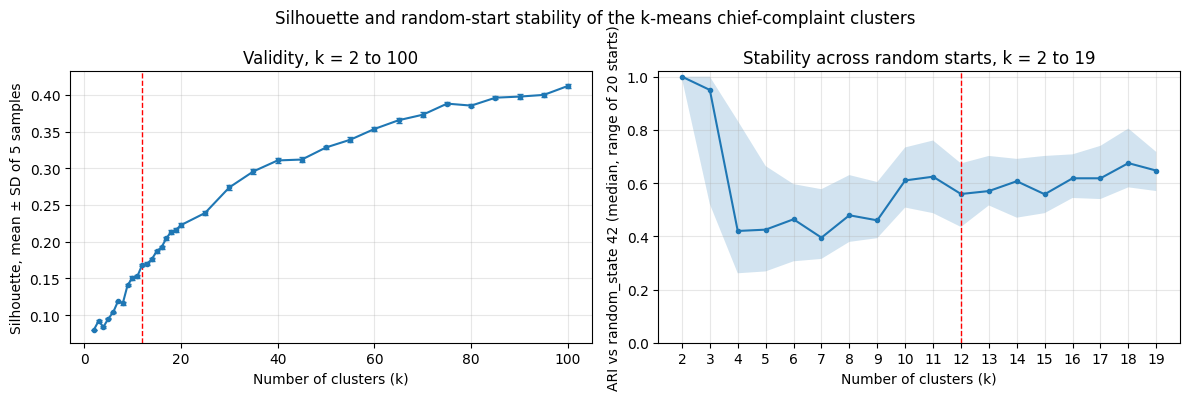

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(validity.k, validity.silhouette_mean, yerr=validity.silhouette_sd, marker='o', ms=3, capsize=2)
ax[0].set_ylabel('Silhouette, mean ± SD of 5 samples'); ax[0].set_title('Validity, k = 2 to 100')
ax[1].plot(stab_summary.index, stab_summary['median'], marker='o', ms=3)
ax[1].fill_between(stab_summary.index, stab_summary['min'], stab_summary['max'], alpha=.2)
ax[1].set_ylim(0, 1.02); ax[1].set_xticks(list(STAB_K_RANGE))
ax[1].set_ylabel('ARI vs random_state 42 (median, range of 20 starts)'); ax[1].set_title('Stability across random starts, k = 2 to 19')
for a in ax:
    a.axvline(12, color='red', ls='--', lw=1); a.set_xlabel('Number of clusters (k)'); a.grid(alpha=.3)
fig.suptitle('Silhouette and random-start stability of the k-means chief-complaint clusters')
plt.tight_layout(); fig.savefig(OUT / 'chiefcomp_validity_k.png', dpi=120); plt.show()

Left: mean silhouette (± SD over five samples of 20,000 complaints) for k = 2 to 19 and 20 to 100 in steps of 5. Right: adjusted Rand index between the random_state 42 fit and 20 fits from other random starts, median with the full range, for k = 2 to 19. The dashed red line marks the k = 12 used in the paper. A working figure for the author; the publication figure is drawn in R.

## Alternative-k sensitivity: k = 8 and k = 14

To let the paper test whether its findings depend on the choice of 12 clusters, we build one coarser (k = 8) and one finer (k = 14) solution with the same k-means settings, save the labels, and produce naming aids: cluster sizes, the top n-grams as above, the 10 most frequent cleaned complaints, and a crosstab against the stored 12 clusters (rows use the paper's names). The section reads the cached PCA matrix and the stored labels from disk, so it can run on its own.

In [25]:
t_alt = time.perf_counter()
data = pd.read_parquet('chiefcomp_clustered.parquet', columns=['stay_id', 'cc_cleaned', 'cluster'])
stored = data['cluster'].to_numpy()
X = np.load(PCA_FILE)            # the cached matrix from the PCA section, so this section can run alone
alt_labels = {}
for K in ALT_KS:
    alt_file = OUT / f'chiefcomp_clustered_k{K}.parquet'
    if alt_file.exists():
        alt = pd.read_parquet(alt_file); assert (alt['stay_id'].to_numpy() == data['stay_id'].to_numpy()).all()
        alt_labels[K] = alt[f'cluster_k{K}'].to_numpy(); print(f'Loaded cached k = {K} labels from {alt_file}')
    else:
        alt_labels[K] = make_km(K).fit(X).labels_
        pd.DataFrame({'stay_id': data['stay_id'], f'cluster_k{K}': alt_labels[K]}).to_parquet(alt_file, index=False)
    print(f'k = {K} cluster sizes:'); print(pd.Series(alt_labels[K]).value_counts().sort_index().to_string(), '\n')

Loaded cached k = 8 labels from chiefcomp_clustered_k8.parquet
k = 8 cluster sizes:
0     62280
1     52531
2     17576
3     27945
4     72197
5     45608
6    122961
7     23609 

Loaded cached k = 14 labels from chiefcomp_clustered_k14.parquet
k = 14 cluster sizes:
0     14321
1     30842
2     32025
3     48446
4     20934
5     41794
6     22834
7     59976
8     31285
9     37074
10    15790
11    23282
12    18926
13    27178 



### k = 8

Stored 12 clusters (rows) against the k = 8 clusters (columns), then the naming aid for each k = 8 cluster.

In [26]:
names = [f'{s} {STORED_NAMES[s]}' for s in range(12)]   # ordered 0-11, not alphabetically
stored_named = pd.Series(pd.Categorical([names[s] for s in stored], categories=names), name='stored (k = 12)')
pd.crosstab(stored_named, pd.Series(alt_labels[8], name='k = 8'), margins=True)

k = 8,0,1,2,3,4,5,6,7,All
stored (k = 12),,,,,,,,,
0 Lower back pain,748,1056,591,1550,17601,14665,26,28,36265
1 Influenza like illness,8286,89,35,277,14912,22,6063,21,29705
2 Vehicle collision + Altered mental status,2692,2,51,11,22943,15,22434,39,48187
3 Chest pain + dyspnea,3088,33,3,26074,220,47,6547,0,36012
4 Shortness breath,46551,3,20,6,382,129,1805,3,48899
5 Abdomen pain,70,51062,0,10,131,114,10,2,51399
6 Leg + knee pain,54,1,284,0,201,30341,32,5,30918
7 Wound evaluation,663,53,54,17,15633,212,61054,1,77687
8 Alcohol intoxication,74,180,1,0,30,9,12121,433,12848


In [27]:
naming_aid(8, alt_labels[8])


Cluster 0 (size=62280):
  Most common bigrams/trigrams:
    shortness breath: 3129
    urinary retention: 1486
    dyspnea exertion: 1385
    influenza like: 1282
    like illness: 1282
    influenza like illness: 1282
    asthma exacerbation: 1167
    cough dyspnea: 877
    unable ambulate: 866
    slurred speech: 740


  Most common cleaned complaints: 'dyspnea' (7426); 'weakness' (3527); 'dizziness' (3020); 'shortness breath' (2238); 'palpitations' (1929); 'cough' (1925); 'dysuria' (1390); 'diarrhea' (1139); 'urinary retention' (1105); 'asthma exacerbation' (829)

Cluster 1 (size=52531):
  Most common bigrams/trigrams:
    abdomen pain: 28987
    abdominal pain: 11830
    quadrant abdominal: 6449
    quadrant abdominal pain: 6447
    flank pain: 6101
    lower quadrant: 4588
    lower quadrant abdominal: 4459
    upper quadrant: 2749
    pain transfer: 2120
    upper quadrant abdominal: 1989
  Most common cleaned complaints: 'abdomen pain' (15996); 'flank pain' (3505); 'lower quadrant abdominal pain' (2967); 'abdominal pain' (2002); 'abdomen pain transfer' (1560); 'upper quadrant abdominal pain' (1228); 'epigastric pain' (1140); 'lower abdominal pain' (878); 'sided abdominal pain' (799); 'abdomen pain diarrhea' (796)

Cluster 2 (size=17576):
  Most common bigrams/trigrams:
    fall transfer: 1565
  


Cluster 4 (size=72197):
  Most common bigrams/trigrams:
    wound evaluation: 6044
    sore throat: 3893
    neck pain: 3715
    shoulder pain: 3343
    arm pain: 2707
    eye pain: 2043
    ear pain: 1758
    head injury: 1662
    vehicle collision: 1426
    finger laceration: 1423
  Most common cleaned complaints: 'headache' (5722); 'wound evaluation' (5105); 'fever' (3581); 'sore throat' (2186); 'rash' (2171); 'shoulder pain' (1760); 'neck pain' (1473); 'arm pain' (1381); 'finger laceration' (1341); 'eye pain' (1333)

Cluster 5 (size=45608):
  Most common bigrams/trigrams:
    back pain: 12878
    leg pain: 6096
    lower back: 5388
    lower back pain: 5379
    knee pain: 4976
    foot pain: 4079
    leg swelling: 3075
    hip pain: 2180
    ankle pain: 2180
    pain leg: 1619
  Most common cleaned complaints: 'back pain' (4983); 'lower back pain' (3365); 'knee pain' (3084); 'leg pain' (2841); 'foot pain' (2585); 'hip pain' (1524); 'ankle pain' (1460); 'ankle injury' (1171); 'leg 


Cluster 6 (size=122961):
  Most common bigrams/trigrams:
    alcohol intoxication: 10638
    suicidal ideation: 8395
    mental status: 5180
    altered mental: 5057
    altered mental status: 5048
    vehicle collision: 4497
    abnormal labs: 3818
    influenza like: 2644
    like illness: 2644
    influenza like illness: 2644
  Most common cleaned complaints: 'suicidal ideation' (5132); 'alcohol intoxication' (4707); 'vehicle collision' (3637); 'altered mental status' (3169); 'syncope' (2905); 'seizure' (2814); 'influenza like illness' (2452); 'abnormal labs' (2382); 'brbpr' (2296); 'allergic reaction' (1903)

Cluster 7 (size=23609):
  Most common bigrams/trigrams:
    nausea vomiting: 14486
    abdomen pain: 6763
    pain nausea: 5881
    pain nausea vomiting: 4463
    abdomen pain nausea: 4428
    pain vomiting: 1125
    abdomen pain vomiting: 872
    headache nausea: 858
    dizziness nausea: 784
    vomiting abdomen: 744
  Most common cleaned complaints: 'nausea vomiting' (4567

### k = 14

Stored 12 clusters (rows) against the k = 14 clusters (columns), then the naming aid for each k = 14 cluster.

In [28]:
pd.crosstab(stored_named, pd.Series(alt_labels[14], name='k = 14'), margins=True)

k = 14,0,1,2,3,4,5,6,7,8,9,10,11,12,13,All
stored (k = 12),,,,,,,,,,,,,,,
0 Lower back pain,36,255,5,87,1376,76,16535,261,6534,659,156,1,8940,1344,36265
1 Influenza like illness,14022,8,16,289,1920,5,0,4390,4093,4877,0,3,66,16,29705
2 Vehicle collision + Altered mental status,6,14,6002,2846,125,3,0,3073,19935,15902,19,41,217,4,48187
3 Chest pain + dyspnea,10,6,3,190,96,9,19,9118,220,530,2,0,20,25789,36012
4 Shortness breath,122,50,201,42,6177,1,48,41447,258,155,2,13,380,3,48899
5 Abdomen pain,64,80,4,1,3682,41682,5765,28,13,3,0,66,1,10,51399
6 Leg + knee pain,6,30241,0,10,50,0,435,8,7,21,0,0,133,7,30918
7 Wound evaluation,44,91,1345,44954,7471,10,22,1564,90,13553,5,3,8530,5,77687
8 Alcohol intoxication,0,0,12689,5,2,6,2,2,0,3,0,137,2,0,12848


In [29]:
naming_aid(14, alt_labels[14])
print(f'[time] alternative k: {(time.perf_counter() - t_alt) / 60:.2f} min')


Cluster 0 (size=14321):
  Most common bigrams/trigrams:
    like illness: 5152
    influenza like: 5151
    influenza like illness: 5151
    sore throat: 678
    cough fever: 548
    fever influenza: 504
    fever influenza like: 502
    cough influenza: 502
    cough influenza like: 500
    fever cough: 384
  Most common cleaned complaints: 'fever' (3581); 'influenza like illness' (2452); 'cough fever' (359); 'cough influenza like illness' (332); 'fever influenza like illness' (276); 'fever cough' (266); 'fever headache' (265); 'fever transfer' (265); 'fevers' (213); 'fever weakness' (209)

Cluster 1 (size=30842):
  Most common bigrams/trigrams:
    leg pain: 5336
    knee pain: 4958
    foot pain: 4019
    leg swelling: 2918
    ankle pain: 2159
    hip pain: 2006
    ankle injury: 1575
    toe pain: 1125
    calf pain: 973
    bilateral leg: 935
  Most common cleaned complaints: 'knee pain' (3084); 'leg pain' (2841); 'foot pain' (2585); 'hip pain' (1524); 'ankle pain' (1460); 'ankl


Cluster 2 (size=32025):
  Most common bigrams/trigrams:
    alcohol intoxication: 11213
    suicidal ideation: 8532
    mental status: 4272
    altered mental: 4162
    altered mental status: 4154
    unable ambulate: 1623
    intoxication unable: 1471
    alcohol intoxication unable: 1471
    intoxication unable ambulate: 1467
    substance use: 1053
  Most common cleaned complaints: 'suicidal ideation' (5132); 'alcohol intoxication' (4707); 'altered mental status' (3169); 'alcohol intoxication unable ambulate' (1423); 'anxiety' (1332); 'hyperglycemia' (1109); 'depression' (846); 'overdose' (631); 'substance use' (595); 'substance misuse intoxication' (447)



Cluster 3 (size=48446):
  Most common bigrams/trigrams:
    abnormal labs: 3253
    psych evaluation: 832
    abnormal ct: 826
    subarachnoid hemorrhage: 808
    unknown cc: 725
    gi bleed: 626
    gtube evaluation: 555
    mental status: 534
    altered mental: 523
    altered mental status: 522
  Most common cleaned complaints: 'abnormal labs' (2382); 'brbpr' (2296); 'cp' (1430); '' (1427); 'hypertension' (1142); 'transfer' (894); 'unknown cc' (725); 'psych evaluation' (711); 'abscess' (608); 'lightheaded' (566)

Cluster 4 (size=20934):
  Most common bigrams/trigrams:
    vaginal bleeding: 2108
    urinary retention: 1699
    rectal pain: 1129
    flank pain: 784
    pelvic pain: 746
    testicular pain: 661
    urinary frequency: 507
    abdominal pain: 439
    lower abdominal: 367
    lower abdominal pain: 367
  Most common cleaned complaints: 'dysuria' (1390); 'hematuria' (1241); 'diarrhea' (1139); 'vaginal bleeding' (1118); 'urinary retention' (1105); 'rectal pain' (788); 'c


Cluster 6 (size=22834):
  Most common bigrams/trigrams:
    back pain: 14368
    abdominal pain: 5656
    lower back: 5619
    lower back pain: 5608
    lower quadrant: 4994
    quadrant abdominal: 4367
    quadrant abdominal pain: 4366
    lower quadrant abdominal: 4365
    lower abdominal: 1288
    lower abdominal pain: 1283
  Most common cleaned complaints: 'back pain' (4983); 'lower back pain' (3365); 'lower quadrant abdominal pain' (2967); 'lower abdominal pain' (878); 'lower extremity pain' (543); 'lower quadrant pain' (446); 'body pain' (355); 'back pain transfer' (278); 'breast pain' (266); 'back pain fall' (255)



Cluster 7 (size=59976):
  Most common bigrams/trigrams:
    shortness breath: 3098
    dyspnea exertion: 1353
    asthma exacerbation: 1141
    unable ambulate: 867
    cough dyspnea: 831
    slurred speech: 798
    mental status: 725
    altered mental: 722
    altered mental status: 722
    abnormal labs: 720
  Most common cleaned complaints: 'dyspnea' (7426); 'weakness' (3527); 'dizziness' (3020); 'syncope' (2905); 'shortness breath' (2238); 'palpitations' (1929); 'cough' (1925); 'epistaxis' (956); 'presyncope' (889); 'asthma exacerbation' (829)

Cluster 8 (size=31285):
  Most common bigrams/trigrams:
    neck pain: 3705
    sore throat: 3318
    shoulder pain: 2425
    eye pain: 1967
    ear pain: 1729
    dental pain: 1002
    vehicle collision: 889
    facial swelling: 841
    facial numbness: 771
    jaw pain: 504
  Most common cleaned complaints: 'headache' (5722); 'sore throat' (2186); 'shoulder pain' (1760); 'neck pain' (1473); 'eye pain' (1333); 'ear pain' (1095); 'dental p


Cluster 9 (size=37074):
  Most common bigrams/trigrams:
    wound evaluation: 5636
    vehicle collision: 5028
    allergic reaction: 2222
    head injury: 1781
    pedestrian struck: 921
    visual changes: 740
    dog bite: 459
    cardiac arrest: 440
    facial droop: 417
    head bleed: 348
  Most common cleaned complaints: 'wound evaluation' (5105); 'vehicle collision' (3637); 'seizure' (2814); 'rash' (2171); 'allergic reaction' (1903); 'head injury' (1211); 'assault' (1126); 'confusion' (922); 'pedestrian struck' (829); 'laceration' (694)

Cluster 10 (size=15790):
  Most common bigrams/trigrams:
    fall transfer: 1525
    head injury: 933
    hip pain: 745
    pain fall: 674
    injury fall: 638
    head injury fall: 544
    fall head: 488
    fracture fall: 483
    hip pain fall: 440
    fall hip: 388
  Most common cleaned complaints: 'fall' (8090); 'fall transfer' (997); 'head injury fall' (511); 'hip pain fall' (419); 'fall head injury' (338); 'fall hip pain' (269); 'lacerat


Cluster 12 (size=18926):
  Most common bigrams/trigrams:
    arm pain: 2661
    finger laceration: 1424
    hand injury: 1394
    wrist pain: 1260
    hand pain: 1129
    finger injury: 1062
    elbow pain: 842
    arm numbness: 831
    pain fall: 711
    shoulder pain: 700
  Most common cleaned complaints: 'arm pain' (1381); 'finger laceration' (1341); 'hand injury' (956); 'finger injury' (820); 'wrist pain' (755); 'hand pain' (656); 'thumb laceration' (483); 'elbow pain' (462); 'hand laceration' (456); 'finger pain' (334)

Cluster 13 (size=27178):
  Most common bigrams/trigrams:
    chest pain: 25887
    pain dyspnea: 2588
    chest pain dyspnea: 2573
    pain transfer: 846
    pain cardiac: 843
    cardiac features: 843
    chest pain cardiac: 843
    pain cardiac features: 843
    chest pain transfer: 824
    rib pain: 615
  Most common cleaned complaints: 'chest pain' (14189); 'chest pain dyspnea' (2004); 'chest pain cardiac features' (843); 'chest pain transfer' (750); 'rib pain

## Cluster keywords for k = 12, 8 and 14

For every cluster in the stored 12-cluster solution and the k = 8 and k = 14 alternatives we list its name, its size, the 8 most frequent two- and three-word phrases (counted as above), the 8 most distinctive phrases by TF-IDF, and the 8 most frequent whole cleaned complaints. The names are the ones chosen by the author (k = 12: the names used in the paper; k = 8 and 14: chosen from the naming aids above). The phrase counts behind TF-IDF are built once on all 424,707 complaints; "cc" is dropped because it is an abbreviation for "chief complaint" and means nothing on its own. The section reads the stored labels and the k = 8 / k = 14 parquets from disk, so it runs on its own.

In [30]:
t_kw = time.perf_counter()
data = pd.read_parquet('chiefcomp_clustered.parquet', columns=['stay_id', 'cc_cleaned', 'cluster'])
stored = data['cluster'].to_numpy()
kw_labels = {12: (stored, STORED_NAMES)}
for K, names in [(8, K8_NAMES), (14, K14_NAMES)]:
    alt = pd.read_parquet(OUT / f'chiefcomp_clustered_k{K}.parquet')
    assert (alt['stay_id'].to_numpy() == data['stay_id'].to_numpy()).all()   # same row order as the stored file
    kw_labels[K] = (alt[f'cluster_k{K}'].to_numpy(), names)
# one complaint x phrase count matrix for all complaints, so phrases never cross complaint boundaries
cv = CountVectorizer(ngram_range=(1,3), min_df=20, token_pattern=r'(?u)\b\w+\b', stop_words=['cc'])
kw_counts = cv.fit_transform(data['cc_cleaned'].fillna('')).tocsr()
kw_terms = cv.get_feature_names_out()
print('Phrase vocabulary (1-3 words, in >= 20 complaints):', len(kw_terms), '| matrix', kw_counts.shape)
keywords = pd.concat([keyword_table(K, lab, names) for K, (lab, names) in kw_labels.items()], ignore_index=True)
keywords.to_csv(OUT / 'chiefcomp_keywords.csv', index=False)
print('Saved', OUT / 'chiefcomp_keywords.csv', keywords.shape)

Phrase vocabulary (1-3 words, in >= 20 complaints): 4071 | matrix (424707, 4071)


Saved chiefcomp_keywords.csv (34, 7)


### Stored k = 12 (paper)

In [31]:
with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    print(keywords.query('k == 12').drop(columns='k').to_string(index=False))

 cluster                                      name  size                                                                                                                                                                                                                                  top_phrases                                                                                                                                                                                                                                                    tfidf_phrases                                                                                                                                                                                                                                                                        top_complaints
       0                           Lower back pain 36265                                                                            back pain (14,977); lower back (5,213);

### k = 8

In [32]:
with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    print(keywords.query('k == 8').drop(columns='k').to_string(index=False))

 cluster      name   size                                                                                                                                                                                                       top_phrases                                                                                                                                                                                                                                 tfidf_phrases                                                                                                                                                                                                                      top_complaints
       0 Cluster 0  62280     shortness breath (3,129); urinary retention (1,486); dyspnea exertion (1,385); influenza like (1,282); like illness (1,282); influenza like illness (1,282); asthma exacerbation (1,167); cough dyspnea (877) palpitations irregular heart (0.06); palpitations irregular (0

### k = 14

In [33]:
with pd.option_context('display.max_colwidth', None, 'display.width', 250):
    print(keywords.query('k == 14').drop(columns='k').to_string(index=False))
print(f'[time] keywords: {(time.perf_counter() - t_kw) / 60:.2f} min')

 cluster       name  size                                                                                                                                                                                                                       top_phrases                                                                                                                                                                                                                                    tfidf_phrases                                                                                                                                                                                                            top_complaints
       0  Cluster 0 14321                                      like illness (5,152); influenza like (5,151); influenza like illness (5,151); sore throat (678); cough fever (548); fever influenza (504); fever influenza like (502); cough influenza (502)                           like illnes

## Run time

Wall time per section and in total, in minutes, on this machine. On a first run the PCA takes about a minute, the validity scan about an hour and the stability loop about 80 minutes; later runs load the saved files and finish in a few minutes.

In [34]:
TIMES['total'] = round((time.perf_counter() - T0) / 60, 2)
pd.Series(TIMES, name='minutes').to_frame()

,minutes
setup,0.00
pca,0.00
reproducibility,0.22
validity,0.00
stability,0.00
total,0.31
